# Ejemplo en el que se entrena una GAN para generar imágenes del dataset MNIST (dígitos manuscritos).

In [ ]:
!pip install torch torchvision

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/


In [ ]:
"""
Author: Jamal Toutouh (www.jamal.es)

It contains the code to show an example about using GANs.
The GAN is used to generate samples of MNIST dataset (handwriten digits).
"""

import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision import transforms
from torchvision.utils import save_image
import numpy as np
import datetime
import os, sys
from matplotlib.pyplot import imshow, imsave
%matplotlib inline

Tareas previas:
- Darle nombre al modelo
- Configurar el entorno de ejecución para que funcione tanto si existe **GPU** como si no (se ejecutará en CPU)

In [ ]:
MODEL_NAME = 'SimpleGAN'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Función auxiliar para crear 100 imágenes sintéticas generadas por el Generador *G*

In [ ]:
# Function to create 100 fake samples generated by the Generator
def get_sample_image(G, z_size):
    z = torch.randn(100, z_size).to(DEVICE)
    y_hat = G(z).view(100, 28, 28) # (100, 28, 28)
    result = y_hat.cpu().data.numpy()
    img = np.zeros([280, 280])
    for j in range(10):
        img[j*28:(j+1)*28] = np.concatenate([x for x in result[j*10:(j+1)*10]], axis=-1)
    return img

Clase para definir un Discriminador simple, arquitectura MLP con tres capas




In [ ]:
class Discriminator(nn.Module):
    def __init__(self, input_size=784, output_size=1):
        super(Discriminator, self).__init__()
        self.layer = nn.Sequential(
            nn.Linear(input_size, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, output_size),
            nn.Sigmoid(),
        )

    def forward(self, x):
        y_ = x.view(x.size(0), -1)
        y_ = self.layer(y_)
        return y_

Clase para definir un Generador simple, arquitectura MLP cinco capas

In [ ]:
class Generator(nn.Module):
    def __init__(self, input_size=100, output_size=784):
        super(Generator, self).__init__()
        self.layer = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, output_size),
            nn.Tanh()
        )

    def forward(self, x):
        y_ = self.layer(x)
        y_ = y_.view(x.size(0), 1, 28, 28)
        return y_

Definimos las variables que instancian el Discriminador y el Generador

In [ ]:
discriminator = Discriminator().to(DEVICE)    # Discriminator ANN

z_size = 100   # Size of the latent space vector
generator = Generator(z_size).to(DEVICE)  # Generator ANN

Obtener datos (MNIST)

In [ ]:
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize(mean=[0.5],std=[0.5])]
)

mnist = datasets.MNIST(root='../data/', train=True, transform=transform, download=True)
batch_size = 100
data_loader = DataLoader(dataset=mnist, batch_size=batch_size, shuffle=True, drop_last=True)

  0%|          | 0/9912422 [00:00<?, ?it/s]

Extracting ../data/MNIST/raw/train-images-idx3-ubyte.gz to ../data/MNIST/raw



  0%|          | 0/28881 [00:00<?, ?it/s]

Extracting ../data/MNIST/raw/train-labels-idx1-ubyte.gz to ../data/MNIST/raw



  0%|          | 0/1648877 [00:00<?, ?it/s]

Extracting ../data/MNIST/raw/t10k-images-idx3-ubyte.gz to ../data/MNIST/raw



  0%|          | 0/4542 [00:00<?, ?it/s]

Extracting ../data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ../data/MNIST/raw



Preparación del entrenamiento

In [ ]:
criterion = nn.BCELoss()
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
max_epoch = 10
n_critic = 1 # Steps to train the discriminator before to train the generator
D_labels = torch.ones(batch_size, 1).to(DEVICE) # Discriminator Label to real
D_fakes = torch.zeros(batch_size, 1).to(DEVICE) # Discriminator Label to fake
if not os.path.exists('samples'):
    os.makedirs('samples')

In [ ]:
for epoch in range(max_epoch):
    for batch_idx, (images, _) in enumerate(data_loader):
        # Discrimiantor training
        x = images.to(DEVICE)
        x_outputs = discriminator(x)
        discriminator_x_loss = criterion(x_outputs, D_labels)

        z = torch.randn(batch_size, z_size).to(DEVICE)
        z_outputs = discriminator(generator(z))
        discriminator_z_loss = criterion(z_outputs, D_fakes)

        discriminator_loss = discriminator_x_loss + discriminator_z_loss

        discriminator.zero_grad()
        discriminator_loss.backward()
        discriminator_optimizer.step()

        if batch_idx % n_critic == 0:
            # Generator training
            z = torch.randn(batch_size, z_size).to(DEVICE)
            z_outputs = discriminator(generator(z))
            generator_loss = criterion(z_outputs, D_labels)

            generator.zero_grad()
            generator_loss.backward()
            generator_optimizer.step()

        if batch_idx % 100 == 0:
            print('Epoch: {}/{}, Batch: {}, Discriminator Loss: {}, Generator Loss: {}'.format(epoch, max_epoch, batch_idx, discriminator_loss.item(), generator_loss.item()))

    generator.eval()
    img = get_sample_image(generator, z_size)
    imsave('samples/{}_epoch{}.jpg'.format(MODEL_NAME, str(epoch).zfill(3)), img, cmap='gray')
    generator.train()


Epoch: 0/10, Batch: 0, Discriminator Loss: 1.1357718706130981, Generator Loss: 0.6010342836380005
Epoch: 0/10, Batch: 100, Discriminator Loss: 1.2872918844223022, Generator Loss: 0.8887084722518921
Epoch: 0/10, Batch: 200, Discriminator Loss: 1.2884573936462402, Generator Loss: 0.5392212867736816
Epoch: 0/10, Batch: 300, Discriminator Loss: 1.2684762477874756, Generator Loss: 0.8486634492874146
Epoch: 0/10, Batch: 400, Discriminator Loss: 1.187356948852539, Generator Loss: 1.0084598064422607
Epoch: 0/10, Batch: 500, Discriminator Loss: 1.2014260292053223, Generator Loss: 0.7408753633499146
Epoch: 0/10, Batch: 600, Discriminator Loss: 1.2075610160827637, Generator Loss: 1.158478856086731
Epoch: 0/10, Batch: 700, Discriminator Loss: 1.2546755075454712, Generator Loss: 1.2886618375778198
Epoch: 0/10, Batch: 800, Discriminator Loss: 1.1473581790924072, Generator Loss: 0.9252779483795166
Epoch: 0/10, Batch: 900, Discriminator Loss: 1.133732795715332, Generator Loss: 1.0584022998809814
Epoch

**Visualización** de resultado

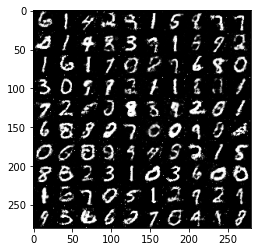

In [ ]:
generator.eval()
imshow(get_sample_image(generator, z_size), cmap='gray')

Salvar los parámetros encontrados

In [ ]:
torch.save(discriminator.state_dict(), 'D.pkl')
torch.save(generator.state_dict(), 'G.pkl')

In [ ]:
%ls samples/

SimpleGAN_epoch000.jpg  SimpleGAN_epoch004.jpg  SimpleGAN_epoch008.jpg
SimpleGAN_epoch001.jpg  SimpleGAN_epoch005.jpg  SimpleGAN_epoch009.jpg
SimpleGAN_epoch002.jpg  SimpleGAN_epoch006.jpg
SimpleGAN_epoch003.jpg  SimpleGAN_epoch007.jpg


Análisis de la evolución de la calidad de soluciones

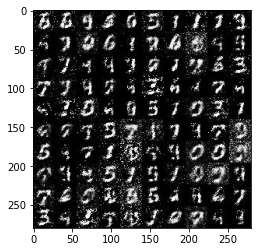

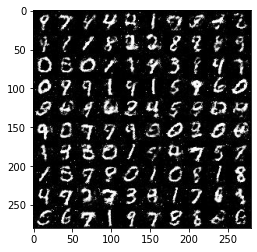

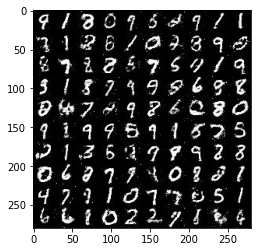

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread('samples/SimpleGAN_epoch000.jpg')
imgplot = plt.imshow(img)
plt.show()
img = mpimg.imread('samples/SimpleGAN_epoch005.jpg')
imgplot = plt.imshow(img)
plt.show()
img = mpimg.imread('samples/SimpleGAN_epoch009.jpg')
imgplot = plt.imshow(img)
plt.show()

In [ ]:
img = mpimg.imread('samples/SimpleGAN_step46000.jpg')
imgplot = plt.imshow(img)
plt.show()